# 🛡️ FraudLake — Jour 3 : Spark SQL avancé, rigueur statistique & Couche Gold

| Bronze (J1) | Silver (J2) | Gold (J3) | Statistiques, ML & Dashboard (J4) |
|:---:|:---:|:---:|:---:|
| ingestion brute + lignage ✅ | nettoyage, pseudonymisation, features ✅ | **▶ KPI & agrégats SQL** | tests, segmentation, scoring |

### 🎯 Objectifs de la séance
1. Diagnostiquer l'**asymétrie** des montants (`SKEWNESS`) et justifier les indicateurs robustes (**médiane**, **IQR**, **P90/P95**).
2. Écrire des requêtes **Spark SQL avancées** : CTE, `GROUPING SETS`, `DENSE_RANK`, cumul de **Pareto**, `LAG`, moyennes glissantes, `ROW_NUMBER`.
3. Alimenter **7 tables Gold** prêtes pour le dashboard + un **catalogue de données** (`data_catalog`) documentant chaque requête.
4. Traiter le *Small Files Problem* : `OPTIMIZE … ZORDER BY` sur la table Silver.

### 🥇 Tables Gold produites
| Table | Grain | Usage dashboard |
|---|---|---|
| `amount_distribution` | classe (fraude / légitime / ensemble) | KPI montants, justification médiane |
| `fraud_by_category` | catégorie | Pareto des pertes, comparaison des médianes |
| `fraud_daily` | jour | courbe temporelle, moyenne glissante 7 j, jours fériés |
| `fraud_monthly` | mois | croissance mois sur mois (`LAG`) |
| `fraud_hour_weekday` | jour de semaine × heure | carte de chaleur du risque |
| `fraud_by_state` | État US | carte choroplèthe, IC de Wilson, catégorie dominante |
| `transactions_sample` | transaction (échantillon stratifié pondéré) | distributions interactives |

In [1]:
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # pandas 3 / PySpark : avertissement sans impact
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
    SparkSession.builder
    .appName("J3_Analytics_SQL_Gold")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

SILVER_MAIN_PATH = "/lakehouse/silver/transactions_enriched"
GOLD_ROOT = "/lakehouse/gold"
spark.read.format("delta").load(SILVER_MAIN_PATH).createOrReplaceTempView("v_silver")
print("Lignes disponibles dans v_silver :", f"{spark.sql('SELECT COUNT(*) FROM v_silver').collect()[0][0]:,}")

GOLD_CATALOG: list[dict] = []   # documentation vivante : alimentée à chaque table Gold, lue par le dashboard


def save_gold(df, name: str, description: str, sql: str, n_files: int = 1) -> str:
    """Écrit une table Gold compacte (coalesce) en Delta et la documente dans le catalogue."""
    path = f"{GOLD_ROOT}/{name}"
    df.coalesce(n_files).write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(path)
    GOLD_CATALOG.append({"table_name": name, "path": path, "description": description, "sql": sql.strip(),
                         "producer": "J3_Analytics_SQL_Gold"})
    print(f"🥇 {path:<38} {spark.read.format('delta').load(path).count():>8,} lignes")
    return path

# --- Charte graphique commune aux notebooks FraudLake --------------------------
import warnings

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)   # avertissements pandas 3 / PySpark sans impact

LEGIT, FRAUD, NEUTRAL = "#2a78d6", "#eb6834", "#9a9893"   # bleu = légitime, orange = fraude
CLASS_COLORS = {"Légitime": LEGIT, "Fraude": FRAUD}
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.titlelocation": "left",
    "grid.color": "#e6e5e1",
    "legend.frameon": False,
})

:: loading settings :: url = jar:file:/opt/venv/lib/python3.15/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
io.delta#delta-spark_4.2_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-396eca06-3e76-4e86-8abd-a1f76b8a17d2;1.0
	confs: [default]
	found io.delta#delta-spark_4.2_2.13;4.4.1 in central
	found io.delta#delta-storage;4.4.1 in central
	found io.unitycatalog#unitycatalog-client;0.6.0 in central
	found org.slf4j#slf4j-api;2.0.13 in central


	found org.apache.logging.log4j#log4j-slf4j2-impl;2.25.3 in central
	found org.apache.logging.log4j#log4j-api;2.25.3 in central
	found com.google.code.findbugs#jsr305;3.0.2 in central
	found io.unitycatalog#unitycatalog-hadoop;0.6.0 in central
	found org.apache.logging.log4j#log4j-core;2.25.3 in central
	found io.delta#delta-kernel-api;4.4.1 in central
	found org.roaringbitmap#RoaringBitmap;0.9.25 in central
	found com.fasterxml.jackson.core#jackson-databind;2.13.5 in central
	found com.fasterxml.jackson.core#jackson-annotations;2.13.5 in central
	found com.fasterxml.jackson.core#jackson-core;2.13.5 in central
	found com.fasterxml.jackson.datatype#jackson-datatype-jdk8;2.13.5 in central
	found org.roaringbitmap#shims;0.9.25 in central
	found io.delta#delta-kernel-defaults;4.4.1 in central
	found org.apache.hadoop#hadoop-client-runtime;3.4.2 in central
	found org.apache.parquet#parquet-hadoop;1.16.0 in central


	found org.apache.parquet#parquet-column;1.16.0 in central
	found org.apache.parquet#parquet-common;1.16.0 in central
	found org.apache.parquet#parquet-format-structures;1.16.0 in central
	found javax.annotation#javax.annotation-api;1.3.2 in central
	found org.apache.parquet#parquet-encoding;1.16.0 in central
	found org.locationtech.jts#jts-core;1.20.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.7 in central
	found io.airlift#aircompressor;2.0.2 in central
	found commons-pool#commons-pool;1.6 in central
	found com.github.luben#zstd-jni;1.5.7-3 in central
	found org.apache.hadoop#hadoop-client-api;3.4.2 in central
	found commons-logging#commons-logging;1.3.0 in central
	found org.apache.parquet#parquet-jackson;1.16.0 in central
	found io.delta#delta-kernel-unitycatalog;4.4.1 in central
:: resolution report :: resolve 508ms :: artifacts dl 60ms
	:: modules in use:
	com.fasterxml.jackson.core#jackson-annotations;2.13.5 from central in [default]
	com.fasterxml.jackson.core#jacks

:: retrieving :: org.apache.spark#spark-submit-parent-396eca06-3e76-4e86-8abd-a1f76b8a17d2
	confs: [default]
	0 artifacts copied, 33 already retrieved (0kB/8ms)


26/11/21 07:53:52 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Lignes disponibles dans v_silver : 1,852,394


## 1. Analyse d'asymétrie : moyenne vs médiane & écart interquartile

### Exercice 1.1 — Distribution de la métrique principale `amt`
`GROUPING SETS ((is_fraud), ())` calcule **en un seul passage** les statistiques par classe **et** sur l'ensemble.

In [2]:
SQL_DIST = """
SELECT
    CASE WHEN GROUPING(is_fraud) = 1 THEN 'Ensemble'
         WHEN is_fraud = 1 THEN 'Fraude' ELSE 'Légitime' END        AS classe,
    COUNT(*)                                                         AS n,
    ROUND(SUM(amt), 2)                                               AS total_amt,
    ROUND(AVG(amt), 2)                                               AS mean_amt,
    ROUND(STDDEV(amt), 2)                                            AS std_amt,
    ROUND(SKEWNESS(amt), 2)                                          AS skewness,
    ROUND(PERCENTILE_APPROX(amt, 0.25, 10000), 2)                    AS p25,
    ROUND(PERCENTILE_APPROX(amt, 0.50, 10000), 2)                    AS median_amt,
    ROUND(PERCENTILE_APPROX(amt, 0.75, 10000), 2)                    AS p75,
    ROUND(PERCENTILE_APPROX(amt, 0.75, 10000)
        - PERCENTILE_APPROX(amt, 0.25, 10000), 2)                    AS iqr,
    ROUND(PERCENTILE_APPROX(amt, 0.90, 10000), 2)                    AS p90,
    ROUND(PERCENTILE_APPROX(amt, 0.95, 10000), 2)                    AS p95,
    ROUND(MAX(amt), 2)                                               AS max_amt
FROM v_silver
GROUP BY GROUPING SETS ((is_fraud), ())
ORDER BY n DESC
"""
df_dist_summary = spark.sql(SQL_DIST)
df_dist_summary.show(truncate=False)
save_gold(df_dist_summary, "amount_distribution",
          "Statistiques descriptives des montants par classe : moyenne, écart-type, skewness, quartiles, IQR, P90, P95.",
          SQL_DIST)

+--------+-------+--------------+--------+-------+--------+------+----------+-----+------+-------+-------+-------+
|classe  |n      |total_amt     |mean_amt|std_amt|skewness|p25   |median_amt|p75  |iqr   |p90    |p95    |max_amt|
+--------+-------+--------------+--------+-------+--------+------+----------+-----+------+-------+-------+-------+
|Ensemble|1852394|1.2978533201E8|70.06   |159.25 |40.81   |9.65  |47.45     |83.09|73.44 |136.31 |195.23 |28948.9|
|Légitime|1842743|1.2466391872E8|67.65   |153.55 |45.37   |9.61  |47.25     |82.56|72.95 |134.16 |189.54 |28948.9|
|Fraude  |9651   |5121413.29    |530.66  |391.03 |0.03    |239.16|389.57    |902.3|663.14|1024.58|1084.02|1376.04|
+--------+-------+--------------+--------+-------+--------+------+----------+-----+------+-------+-------+-------+



🥇 /lakehouse/gold/amount_distribution           3 lignes


'/lakehouse/gold/amount_distribution'

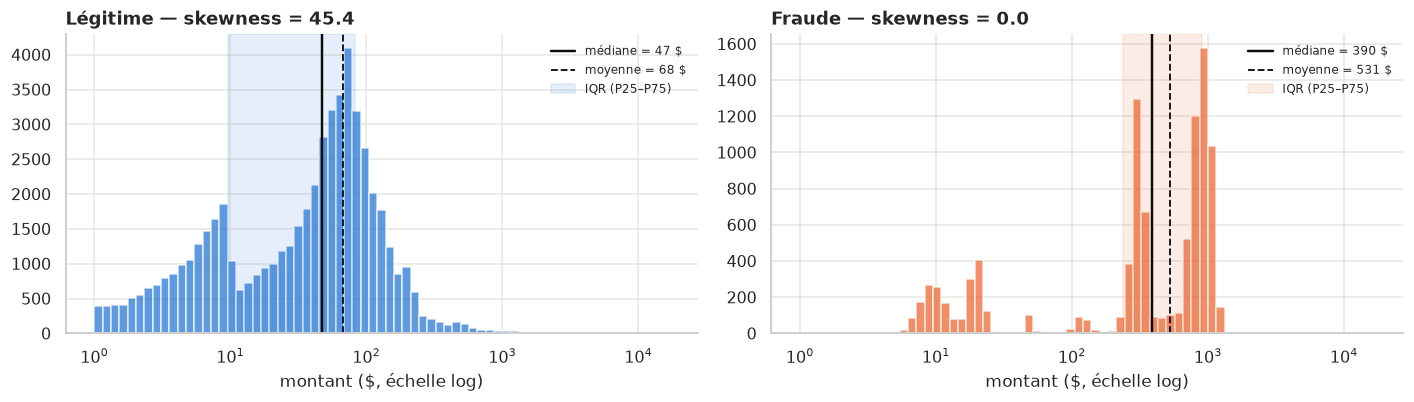

In [3]:
dist_pd = df_dist_summary.toPandas().set_index("classe")
sample_pd = (
    spark.table("v_silver").sampleBy("is_fraud", {0: 0.03, 1: 1.0}, seed=7).select("amt", "is_fraud").toPandas()
)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharex=True)
bins = np.logspace(0, np.log10(sample_pd["amt"].max()), 70)
for ax, (cls, flag) in zip(axes, [("Légitime", 0), ("Fraude", 1)]):
    vals = sample_pd.loc[sample_pd["is_fraud"] == flag, "amt"]
    ax.hist(vals, bins=bins, color=CLASS_COLORS[cls], alpha=0.75)
    ax.axvline(dist_pd.loc[cls, "median_amt"], color="#0b0b0b", lw=1.6, label=f"médiane = {dist_pd.loc[cls, 'median_amt']:.0f} $")
    ax.axvline(dist_pd.loc[cls, "mean_amt"], color="#0b0b0b", lw=1.2, ls="--", label=f"moyenne = {dist_pd.loc[cls, 'mean_amt']:.0f} $")
    ax.axvspan(dist_pd.loc[cls, "p25"], dist_pd.loc[cls, "p75"], color=CLASS_COLORS[cls], alpha=0.12, label="IQR (P25–P75)")
    ax.set_xscale("log")
    ax.set_title(f"{cls} — skewness = {dist_pd.loc[cls, 'skewness']:.1f}")
    ax.set_xlabel("montant ($, échelle log)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 📐 Justification statistique

- **Asymétrie extrême côté légitime** : *skewness* = **45,4** (41 sur l'ensemble ; une loi normale vaut 0). Quelques achats
  exceptionnels (jusqu'à **28 949 $**) tirent la moyenne (**67,7 $**) bien au-dessus de la médiane (**47,2 $**), et l'écart-type
  (153 $) dépasse 2× la moyenne : la moyenne décrit un client « type » qui n'existe pas.
- **La fraude a une distribution différente, pas seulement décalée** : médiane **389,6 $** (≈ 8× la médiane légitime), *skewness*
  quasi nulle (0,03) mais **IQR énorme** (239 → 902 $) et distribution **multimodale** : petits montants de « test de carte »
  (< 30 $), paliers autour de 300 $ puis de 1 000 $ — et un plafond net à 1 376 $ (les fraudeurs restent sous les seuils d'alerte).
- **Choix retenus pour le dashboard** : **médiane** comme indicateur central, **IQR** comme dispersion, **P90 / P95** pour décrire
  la queue. La moyenne n'est conservée que pour les **totaux de pertes** (somme = moyenne × n, grandeur comptable additive).

---
## 2. Table Gold #1 : Pareto des pertes par catégorie (`DENSE_RANK`, cumul fenêtré)

**Question métier :** *quelles catégories concentrent 80 % des montants fraudés ?* Les efforts de contrôle (3-D Secure renforcé,
règles spécifiques) doivent cibler ces catégories en priorité.

In [4]:
SQL_PARETO = """
WITH by_cat AS (
    SELECT
        category,
        COUNT(*)                                                         AS n_txn,
        SUM(is_fraud)                                                    AS n_fraud,
        ROUND(SUM(amt), 2)                                               AS total_amount,
        ROUND(SUM(CASE WHEN is_fraud = 1 THEN amt ELSE 0 END), 2)        AS fraud_amount,
        PERCENTILE_APPROX(CASE WHEN is_fraud = 0 THEN amt END, 0.5)      AS median_legit_amt,
        PERCENTILE_APPROX(CASE WHEN is_fraud = 1 THEN amt END, 0.5)      AS median_fraud_amt,
        PERCENTILE_APPROX(CASE WHEN is_fraud = 1 THEN amt END, 0.75)
          - PERCENTILE_APPROX(CASE WHEN is_fraud = 1 THEN amt END, 0.25) AS iqr_fraud_amt
    FROM v_silver
    GROUP BY category
),
ranked AS (
    SELECT *,
        ROUND(100.0 * n_fraud / n_txn, 3)                                AS fraud_rate_pct,
        ROUND(100.0 * fraud_amount / total_amount, 3)                    AS loss_rate_pct,
        DENSE_RANK() OVER (ORDER BY fraud_amount DESC)                   AS loss_rank,
        ROUND(100.0 * SUM(fraud_amount) OVER (ORDER BY fraud_amount DESC
                ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW)
              / SUM(fraud_amount) OVER (), 2)                            AS cum_loss_share_pct
    FROM by_cat
)
SELECT *,
    CASE WHEN cum_loss_share_pct - 100.0 * fraud_amount / SUM(fraud_amount) OVER () < 80
         THEN 'A — 80 % des pertes' ELSE 'B — longue traîne' END        AS pareto_class
FROM ranked
ORDER BY loss_rank
"""
GOLD_PARETO_PATH = f"{GOLD_ROOT}/fraud_by_category"
df_gold_1 = spark.sql(SQL_PARETO)
save_gold(df_gold_1, "fraud_by_category",
          "Pertes et taux de fraude par catégorie, médianes fraude/légitime, rang et cumul de Pareto (classe A = 80 % des pertes).",
          SQL_PARETO)
df_gold_1.select("loss_rank", "category", "n_txn", "n_fraud", "fraud_rate_pct", "fraud_amount", "median_legit_amt",
                 "median_fraud_amt", "cum_loss_share_pct", "pareto_class").show(15, truncate=False)

🥇 /lakehouse/gold/fraud_by_category            14 lignes


+---------+--------------+------+-------+--------------+------------+----------------+----------------+------------------+-------------------+
|loss_rank|category      |n_txn |n_fraud|fraud_rate_pct|fraud_amount|median_legit_amt|median_fraud_amt|cum_loss_share_pct|pareto_class       |
+---------+--------------+------+-------+--------------+------------+----------------+----------------+------------------+-------------------+
|1        |shopping_net  |139322|2219   |1.593         |2214847.64  |8.3             |994.15          |43.25             |A — 80 % des pertes|
|2        |misc_net      |90654 |1182   |1.304         |944009.71   |9.73            |794.06          |61.68             |A — 80 % des pertes|
|3        |shopping_pos  |166463|1056   |0.634         |928132.34   |7.71            |869.58          |79.8              |A — 80 % des pertes|
|4        |grocery_pos   |176191|2228   |1.265         |695664.62   |104.51          |310.23          |93.39             |A — 80 % des pertes|

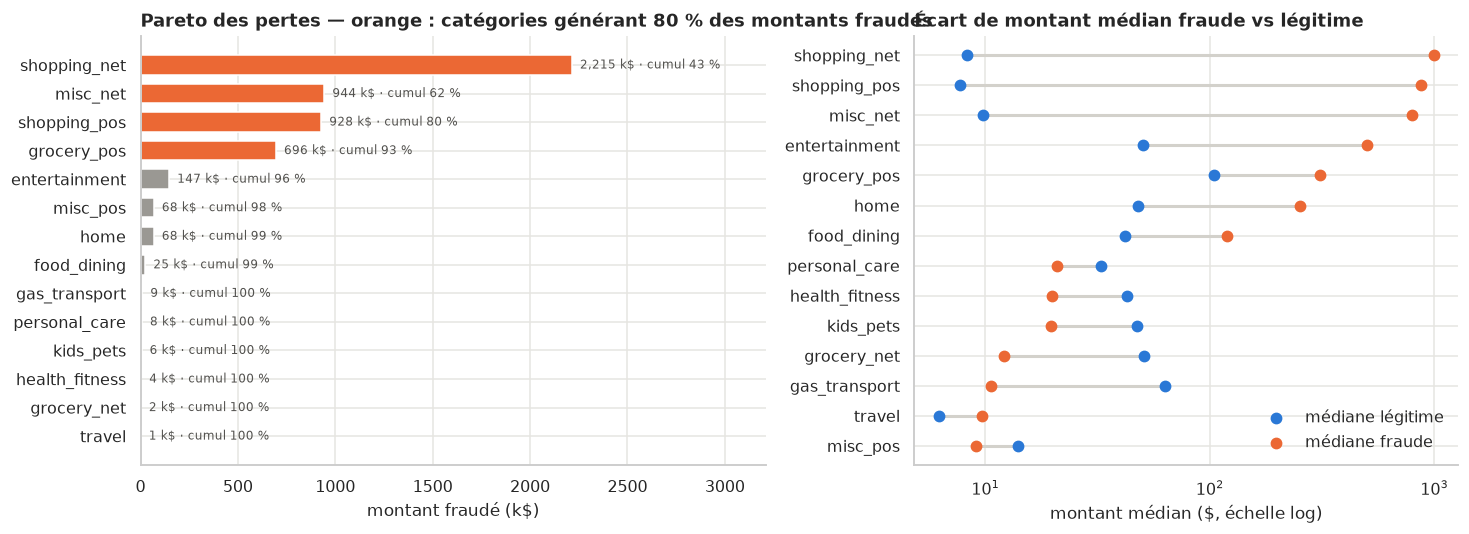

In [5]:
cat_pd = df_gold_1.toPandas().sort_values("fraud_amount")
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5), gridspec_kw={"width_ratios": [1.15, 1]})

ax = axes[0]
colors = [FRAUD if c.startswith("A") else NEUTRAL for c in cat_pd["pareto_class"]]
ax.barh(cat_pd["category"], cat_pd["fraud_amount"] / 1e3, color=colors, height=0.68)
for y, (v, cum) in enumerate(zip(cat_pd["fraud_amount"] / 1e3, cat_pd["cum_loss_share_pct"])):
    ax.text(v, y, f"  {v:,.0f} k$ · cumul {cum:.0f} %", va="center", fontsize=8, color="#52514e")
ax.set_xlim(0, cat_pd["fraud_amount"].max() / 1e3 * 1.45)
ax.set_title("Pareto des pertes — orange : catégories générant 80 % des montants fraudés")
ax.set_xlabel("montant fraudé (k$)")

ax = axes[1]
ordered = cat_pd.sort_values("median_fraud_amt")
y = np.arange(len(ordered))
ax.hlines(y, ordered["median_legit_amt"], ordered["median_fraud_amt"], color="#d3d1cb", lw=2)
ax.scatter(ordered["median_legit_amt"], y, color=LEGIT, s=45, label="médiane légitime", zorder=3)
ax.scatter(ordered["median_fraud_amt"], y, color=FRAUD, s=45, label="médiane fraude", zorder=3)
ax.set_yticks(y, ordered["category"])
ax.set_xscale("log")
ax.set_title("Écart de montant médian fraude vs légitime")
ax.set_xlabel("montant médian ($, échelle log)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 3. Table Gold #2 : dynamique temporelle (`LAG`, moyenne glissante) & effet des jours fériés

Deux granularités complémentaires :
- **quotidienne** : moyenne glissante sur 7 jours (lisse l'effet jour-de-semaine), comparaison à J-7 via `LAG(…, 7)`, marquage des jours fériés issus de la **source n°2** ;
- **mensuelle** : taux de croissance mois sur mois via `LAG(…, 1)`.

In [6]:
SQL_DAILY = """
WITH d AS (
    SELECT
        trans_date,
        COUNT(*)                                                    AS n_txn,
        SUM(is_fraud)                                               AS n_fraud,
        ROUND(SUM(amt), 2)                                          AS total_amount,
        ROUND(SUM(CASE WHEN is_fraud = 1 THEN amt ELSE 0 END), 2)   AS fraud_amount,
        MAX(is_holiday)                                             AS is_holiday,
        MAX(CASE WHEN is_holiday = 1 THEN nearest_holiday END)      AS holiday_name,
        MIN(days_to_holiday)                                        AS days_to_holiday
    FROM v_silver
    GROUP BY trans_date
)
SELECT *,
    ROUND(100.0 * n_fraud / n_txn, 3)                                               AS fraud_rate_pct,
    ROUND(AVG(n_fraud) OVER (ORDER BY trans_date ROWS BETWEEN 6 PRECEDING AND CURRENT ROW), 2) AS n_fraud_ma7,
    ROUND(AVG(fraud_amount) OVER (ORDER BY trans_date ROWS BETWEEN 6 PRECEDING AND CURRENT ROW), 2) AS fraud_amount_ma7,
    LAG(n_fraud, 7) OVER (ORDER BY trans_date)                                      AS n_fraud_lag7,
    ROUND(100.0 * (n_fraud - LAG(n_fraud, 7) OVER (ORDER BY trans_date))
          / NULLIF(LAG(n_fraud, 7) OVER (ORDER BY trans_date), 0), 1)               AS wow_growth_pct
FROM d
ORDER BY trans_date
"""
SQL_MONTHLY = """
WITH m AS (
    SELECT
        trans_month,
        COUNT(*)                                                    AS n_txn,
        SUM(is_fraud)                                               AS n_fraud,
        ROUND(SUM(amt), 2)                                          AS total_amount,
        ROUND(SUM(CASE WHEN is_fraud = 1 THEN amt ELSE 0 END), 2)   AS fraud_amount
    FROM v_silver
    GROUP BY trans_month
)
SELECT *,
    ROUND(100.0 * n_fraud / n_txn, 3)                                               AS fraud_rate_pct,
    LAG(n_fraud, 1) OVER (ORDER BY trans_month)                                     AS n_fraud_prev_month,
    ROUND(100.0 * (n_fraud - LAG(n_fraud, 1) OVER (ORDER BY trans_month))
          / NULLIF(LAG(n_fraud, 1) OVER (ORDER BY trans_month), 0), 1)              AS mom_fraud_growth_pct,
    ROUND(100.0 * (fraud_amount - LAG(fraud_amount, 1) OVER (ORDER BY trans_month))
          / NULLIF(LAG(fraud_amount, 1) OVER (ORDER BY trans_month), 0), 1)         AS mom_loss_growth_pct
FROM m
ORDER BY trans_month
"""
GOLD_TIME_PATH = f"{GOLD_ROOT}/fraud_daily"
df_gold_2 = spark.sql(SQL_DAILY)
save_gold(df_gold_2, "fraud_daily",
          "Série quotidienne : volumes, fraudes, pertes, moyenne glissante 7 j, variation vs J-7 (LAG) et jours fériés.",
          SQL_DAILY)
df_gold_2m = spark.sql(SQL_MONTHLY)
save_gold(df_gold_2m, "fraud_monthly",
          "Série mensuelle : taux de fraude et croissance mois sur mois des fraudes et des pertes (LAG).", SQL_MONTHLY)
df_gold_2m.show(24, truncate=False)

🥇 /lakehouse/gold/fraud_daily                 730 lignes


🥇 /lakehouse/gold/fraud_monthly                24 lignes


+-----------+------+-------+------------+------------+--------------+------------------+--------------------+-------------------+
|trans_month|n_txn |n_fraud|total_amount|fraud_amount|fraud_rate_pct|n_fraud_prev_month|mom_fraud_growth_pct|mom_loss_growth_pct|
+-----------+------+-------+------------+------------+--------------+------------------+--------------------+-------------------+
|2019-01    |52525 |506    |3759750.03  |261780.38   |0.963         |NULL              |NULL                |NULL               |
|2019-02    |49866 |517    |3604662.23  |274051.08   |1.037         |506               |2.2                 |4.7                |
|2019-03    |70939 |494    |5027886.4   |237637.59   |0.696         |517               |-4.4                |-13.3              |
|2019-04    |68078 |376    |4761504.58  |202067.29   |0.552         |494               |-23.9               |-15.0              |
|2019-05    |72532 |408    |5060903.32  |210549.11   |0.563         |376               |8.

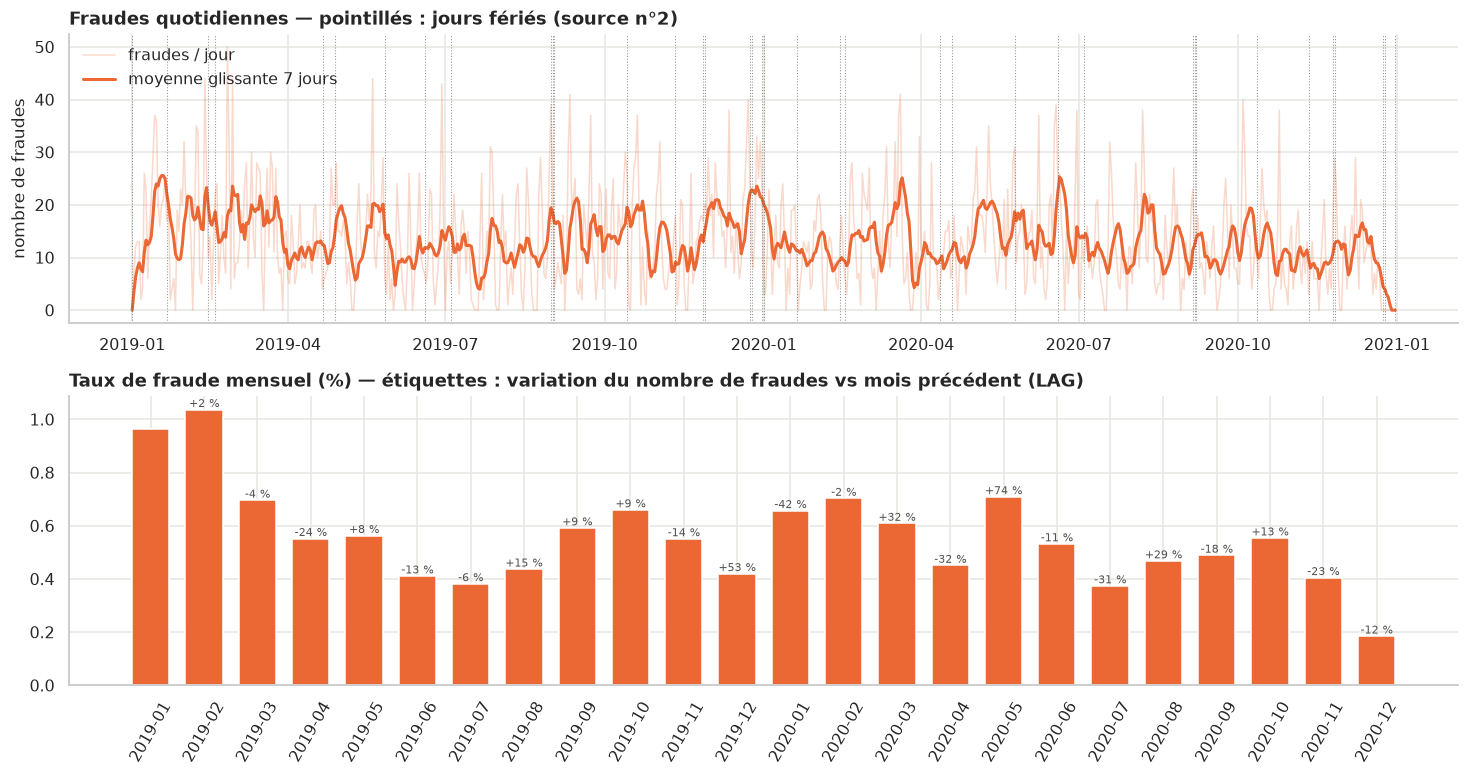

In [7]:
daily_pd = df_gold_2.toPandas()
daily_pd["trans_date"] = pd.to_datetime(daily_pd["trans_date"])
monthly_pd = df_gold_2m.toPandas()

fig, axes = plt.subplots(2, 1, figsize=(13.5, 7.2))
ax = axes[0]
ax.plot(daily_pd["trans_date"], daily_pd["n_fraud"], color=FRAUD, alpha=0.25, lw=1, label="fraudes / jour")
ax.plot(daily_pd["trans_date"], daily_pd["n_fraud_ma7"], color=FRAUD, lw=2, label="moyenne glissante 7 jours")
for _, h in daily_pd[daily_pd["is_holiday"] == 1].iterrows():
    ax.axvline(h["trans_date"], color="#52514e", lw=0.7, ls=":", alpha=0.6)
ax.set_title("Fraudes quotidiennes — pointillés : jours fériés (source n°2)")
ax.set_ylabel("nombre de fraudes")
ax.legend(loc="upper left")

ax = axes[1]
ax.bar(monthly_pd["trans_month"], monthly_pd["fraud_rate_pct"], color=FRAUD, width=0.7)
for x, (v, g) in enumerate(zip(monthly_pd["fraud_rate_pct"], monthly_pd["mom_fraud_growth_pct"])):
    if pd.notna(g):
        ax.text(x, v, f"{g:+.0f} %", ha="center", va="bottom", fontsize=7, color="#52514e")
ax.set_title("Taux de fraude mensuel (%) — étiquettes : variation du nombre de fraudes vs mois précédent (LAG)")
ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

> **Lecture.** La fraude n'est pas stationnaire : le taux culmine en **janvier – février 2019 (≈ 1 %)** puis oscille entre 0,4 et 0,7 %
> avec des variations mensuelles de ± 30 à 75 %. **Décembre est le piège classique** : le volume de transactions double (≈ 140 000 contre
> ≈ 70 000) et le *nombre* de fraudes grimpe (+53 % en déc. 2019), alors que le **taux** chute (0,42 % en 2019, 0,19 % en 2020).
> Il faut donc piloter la surveillance sur le **taux**, sinon chaque fin d'année déclencherait une fausse alerte.

---
## 4. Tables Gold #3 : carte de chaleur horaire & profil géographique (`ROW_NUMBER() OVER (PARTITION BY …)`)

Pour le profil par État, les petits États (peu de transactions) produisent des taux extrêmes et instables. Nous calculons
l'**intervalle de confiance de Wilson à 95 %** directement en SQL : le dashboard classera les États sur la **borne basse**,
un classement prudent qui ne met pas en tête un État à 3 fraudes sur 9 transactions.
$$\text{Wilson}_{\pm} = \frac{\hat p + \frac{z^2}{2n} \pm z\sqrt{\frac{\hat p(1-\hat p)}{n} + \frac{z^2}{4n^2}}}{1 + \frac{z^2}{n}},\quad z = 1{,}96$$

In [8]:
SQL_HEATMAP = """
SELECT
    weekday_num,
    ELT(weekday_num, 'Lun', 'Mar', 'Mer', 'Jeu', 'Ven', 'Sam', 'Dim')   AS weekday_label,
    hour,
    COUNT(*)                                                         AS n_txn,
    SUM(is_fraud)                                                    AS n_fraud,
    ROUND(100.0 * AVG(is_fraud), 3)                                  AS fraud_rate_pct,
    ROUND(SUM(CASE WHEN is_fraud = 1 THEN amt ELSE 0 END), 2)        AS fraud_amount
FROM v_silver
GROUP BY weekday_num, hour
ORDER BY weekday_num, hour
"""
SQL_STATE = """
WITH state_cat AS (
    SELECT state, category, COUNT(*) AS n_txn, SUM(is_fraud) AS n_fraud,
           SUM(CASE WHEN is_fraud = 1 THEN amt ELSE 0 END) AS fraud_amount
    FROM v_silver
    GROUP BY state, category
),
top_cat AS (
    SELECT state, category AS top_fraud_category, n_fraud AS top_category_frauds,
           ROW_NUMBER() OVER (PARTITION BY state ORDER BY n_fraud DESC, fraud_amount DESC) AS rn
    FROM state_cat
),
by_state AS (
    SELECT state, SUM(n_txn) AS n_txn, SUM(n_fraud) AS n_fraud, ROUND(SUM(fraud_amount), 2) AS fraud_amount
    FROM state_cat
    GROUP BY state
)
SELECT
    s.state, s.n_txn, s.n_fraud, s.fraud_amount,
    ROUND(100.0 * s.n_fraud / s.n_txn, 3)                                            AS fraud_rate_pct,
    ROUND(100.0 * ((s.n_fraud / s.n_txn) + 1.96 * 1.96 / (2 * s.n_txn)
          - 1.96 * SQRT((s.n_fraud / s.n_txn) * (1 - s.n_fraud / s.n_txn) / s.n_txn + 1.96 * 1.96 / (4 * s.n_txn * s.n_txn)))
          / (1 + 1.96 * 1.96 / s.n_txn), 3)                                          AS wilson_low_pct,
    ROUND(100.0 * ((s.n_fraud / s.n_txn) + 1.96 * 1.96 / (2 * s.n_txn)
          + 1.96 * SQRT((s.n_fraud / s.n_txn) * (1 - s.n_fraud / s.n_txn) / s.n_txn + 1.96 * 1.96 / (4 * s.n_txn * s.n_txn)))
          / (1 + 1.96 * 1.96 / s.n_txn), 3)                                          AS wilson_high_pct,
    t.top_fraud_category,
    ROUND(100.0 * t.top_category_frauds / NULLIF(s.n_fraud, 0), 1)                   AS top_category_share_pct,
    DENSE_RANK() OVER (ORDER BY s.fraud_amount DESC)                                 AS loss_rank
FROM by_state s
JOIN top_cat t ON s.state = t.state AND t.rn = 1
ORDER BY s.fraud_amount DESC
"""
df_heat = spark.sql(SQL_HEATMAP)
save_gold(df_heat, "fraud_hour_weekday",
          "Taux et montants de fraude par jour de semaine × heure (carte de chaleur du risque).", SQL_HEATMAP)
df_state = spark.sql(SQL_STATE)
save_gold(df_state, "fraud_by_state",
          "Fraude par État : taux, IC de Wilson 95 %, pertes, catégorie la plus fraudée (ROW_NUMBER) et rang des pertes.",
          SQL_STATE)
df_state.show(10, truncate=False)

🥇 /lakehouse/gold/fraud_hour_weekday          168 lignes


🥇 /lakehouse/gold/fraud_by_state               51 lignes


+-----+------+-------+------------+--------------+--------------+---------------+------------------+----------------------+---------+
|state|n_txn |n_fraud|fraud_amount|fraud_rate_pct|wilson_low_pct|wilson_high_pct|top_fraud_category|top_category_share_pct|loss_rank|
+-----+------+-------+------------+--------------+--------------+---------------+------------------+----------------------+---------+
|NY   |119419|730    |395295.32   |0.611         |0.569         |0.657          |shopping_net      |24.0                  |1        |
|TX   |135269|592    |318116.81   |0.438         |0.404         |0.474          |shopping_net      |25.3                  |2        |
|PA   |114173|572    |307432.28   |0.501         |0.462         |0.544          |shopping_net      |27.1                  |3        |
|CA   |80495 |402    |205938.98   |0.499         |0.453         |0.551          |grocery_pos       |28.9                  |4        |
|OH   |66627 |360    |192000.44   |0.540         |0.487       

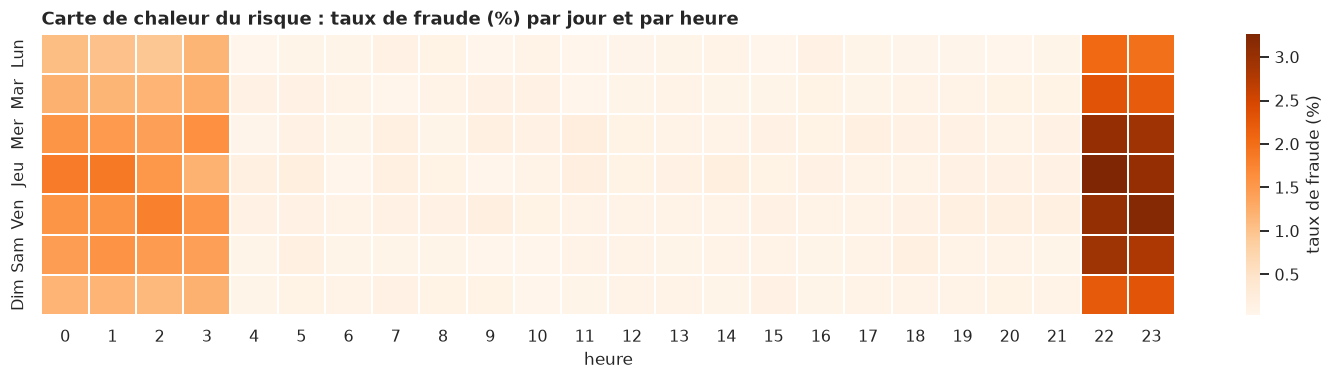

In [9]:
heat_pd = df_heat.toPandas().pivot(index="weekday_label", columns="hour", values="fraud_rate_pct")
heat_pd = heat_pd.loc[["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]]
fig, ax = plt.subplots(figsize=(13.5, 3.6))
sns.heatmap(heat_pd, cmap="Oranges", linewidths=1, linecolor="white", cbar_kws={"label": "taux de fraude (%)"}, ax=ax)
ax.set_title("Carte de chaleur du risque : taux de fraude (%) par jour et par heure")
ax.set_xlabel("heure")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

> **Lecture.** Le risque est **horaire bien plus que hebdomadaire** : ≈ **2,5 %** de fraude entre 22 h et minuit et ≈ **1,3 %** entre
> 0 h et 4 h, contre ≈ **0,1 %** en journée (×13 à ×25), quel que soit le jour. Une règle simple « montant élevé + nuit + e-commerce »
> capterait déjà une large part de la fraude — le modèle du Jour 4 permettra de chiffrer ce gain précisément.

### Table Gold #4 : échantillon stratifié pondéré pour l'exploration interactive
Le dashboard ne doit lire que du Gold (jamais les 1,85 M lignes Silver). Pour permettre histogrammes et nuages de points, on
conserve **toutes les fraudes** et **2 % des transactions légitimes**, avec une colonne `sample_weight` (= 1 / taux de sondage)
qui permet de **ré-estimer sans biais** les totaux et taux de la population.

In [10]:
LEGIT_FRACTION = 0.02
SQL_SAMPLE = f"""
SELECT trans_num, trans_ts, trans_date, trans_month, category, amt, hour, weekday_num, is_night, is_online,
       age, gender, state, distance_km, txn_count_24h, amt_ratio_to_card_mean, days_to_holiday, is_fraud,
       CASE WHEN is_fraud = 1 THEN 1.0 ELSE {1 / LEGIT_FRACTION} END AS sample_weight
FROM v_silver
WHERE is_fraud = 1 OR rand(42) < {LEGIT_FRACTION}
"""
df_sample = spark.sql(SQL_SAMPLE)
save_gold(df_sample, "transactions_sample",
          "Échantillon stratifié : 100 % des fraudes + 2 % des légitimes, pondéré (sample_weight) pour ré-estimer la population.",
          SQL_SAMPLE, n_files=2)
check = df_sample.agg(F.sum("sample_weight").alias("pop_estimee"), F.sum("is_fraud").alias("fraudes")).first()
print(f"Population ré-estimée par pondération : {check['pop_estimee']:,.0f} (réelle : 1 852 394) — fraudes : {check['fraudes']:,}")

🥇 /lakehouse/gold/transactions_sample      46,606 lignes


Population ré-estimée par pondération : 1,857,401 (réelle : 1 852 394) — fraudes : 9,651


## 5. *Small Files Problem* & compaction `OPTIMIZE … ZORDER BY`

Chaque fichier HDFS coûte ≈ 150 octets de **mémoire vive au NameNode**, et chaque fichier lu coûte une ouverture de flux + une
tâche Spark. Les écritures distribuées (et les `MERGE` répétés) produisent beaucoup de petits fichiers : sur un vrai lac de données,
des millions de micro-fichiers saturent le NameNode et ralentissent toutes les lectures.

`OPTIMIZE` réécrit les petits fichiers d'une partition en gros fichiers (~1 Go cible) ; `ZORDER BY (card_id)` co-localise les
transactions d'une même carte, ce qui accélère les investigations « historique d'une carte » grâce au *data skipping*
(statistiques min/max par fichier dans le `_delta_log`). L'opération est **transactionnelle** : les lecteurs ne sont jamais bloqués.

In [11]:
def table_files(path: str) -> dict:
    d = spark.sql(f"DESCRIBE DETAIL delta.`{path}`").select("numFiles", "sizeInBytes").first()
    return {"fichiers": d["numFiles"], "taille_Mo": round(d["sizeInBytes"] / 1024**2, 1)}


before = table_files(SILVER_MAIN_PATH)
optimize_metrics = spark.sql(f"OPTIMIZE delta.`{SILVER_MAIN_PATH}` ZORDER BY (card_id)")
optimize_metrics.select("metrics.numFilesAdded", "metrics.numFilesRemoved", "metrics.totalConsideredFiles").show(truncate=False)
after = table_files(SILVER_MAIN_PATH)

display(pd.DataFrame([{"état": "avant OPTIMIZE", **before}, {"état": "après OPTIMIZE ZORDER", **after}]).style.hide(axis="index"))
print("ℹ️ Les anciens fichiers restent référencés par l'historique (Time Travel) jusqu'à un `VACUUM` (rétention 7 jours par défaut).")

+-------------+---------------+--------------------+
|numFilesAdded|numFilesRemoved|totalConsideredFiles|
+-------------+---------------+--------------------+
|24           |216            |216                 |
+-------------+---------------+--------------------+



état,fichiers,taille_Mo
avant OPTIMIZE,216,163.300000
après OPTIMIZE ZORDER,24,138.600000


ℹ️ Les anciens fichiers restent référencés par l'historique (Time Travel) jusqu'à un `VACUUM` (rétention 7 jours par défaut).


In [12]:
# 📚 Catalogue de données Gold : la documentation (description + SQL) voyage avec les données
catalog_df = spark.createDataFrame(pd.DataFrame(GOLD_CATALOG)).withColumn("updated_at", F.current_timestamp())
catalog_df.write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(f"{GOLD_ROOT}/data_catalog")
spark.read.format("delta").load(f"{GOLD_ROOT}/data_catalog").select("table_name", "description").show(truncate=110)

+-------------------+--------------------------------------------------------------------------------------------------------------+
|         table_name|                                                                                                   description|
+-------------------+--------------------------------------------------------------------------------------------------------------+
|     fraud_by_state| Fraude par État : taux, IC de Wilson 95 %, pertes, catégorie la plus fraudée (ROW_NUMBER) et rang des pertes.|
|  fraud_by_category|Pertes et taux de fraude par catégorie, médianes fraude/légitime, rang et cumul de Pareto (classe A = 80 % ...|
|        fraud_daily|  Série quotidienne : volumes, fraudes, pertes, moyenne glissante 7 j, variation vs J-7 (LAG) et jours fériés.|
|amount_distribution|  Statistiques descriptives des montants par classe : moyenne, écart-type, skewness, quartiles, IQR, P90, P95.|
|      fraud_monthly|                 Série mensuelle : taux de fraud

---
## 🧾 Bilan du Jour 3

- ✅ **Rigueur statistique** : skewness = 45 → médiane + IQR retenus ; montant médian frauduleux ≈ 8× le montant légitime.
- ✅ **Pareto** : **4 catégories sur 14** (`shopping_net`, `misc_net`, `shopping_pos`, `grocery_pos`) génèrent **93 %** des pertes (5,1 M$ fraudés au total).
- ✅ **Temporalité** : la fraude est nocturne (22 h – 4 h, ×13 à ×25) et non stationnaire ; suivi en **taux**, pas en volume.
- ✅ **7 tables Gold + catalogue** documenté, **Silver compactée** (`OPTIMIZE ZORDER BY card_id`).

➡️ **Jour 4** : tests d'hypothèses, segmentation des porteurs, modèle de scoring et dashboard.